# Лабораторная работа 4

Семёнов М.С. 251-952



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Задание

Вариант 29  

|$x$ | 10 | 20 | 30 | 40 | 50 | 60 | 
|:--:|:---:|:---:|:---:|:---:|:---:|:---:|
|$y$ | 1,08 | 1,31 | 1,53 | 1,69 | 1,80 | 1,92 | 


In [2]:
df = pd.DataFrame({'x': [10, 20, 30, 40, 50, 60], 'y': [1.08, 1.31, 1.53, 1.69, 1.80, 1.92]})

df['ln_x'] = np.log(df['x'])
df['ln_y'] = np.log(df['y'])
df['sqr_x'] = df['x'] ** 2

n = len(df)

df

,x,y,ln_x,ln_y,sqr_x
0,10,1.08,2.302585,0.076961,100
1,20,1.31,2.995732,0.270027,400
2,30,1.53,3.401197,0.425268,900
3,40,1.69,3.688879,0.524729,1600
4,50,1.80,3.912023,0.587787,2500
5,60,1.92,4.094345,0.652325,3600


### 1. Линейная функция

Приближаем данные функцией вида: $$y = ax+b$$
Функция ошибок: $$L(a,b)=\sum_{i=1}^{n}(y_i-ax_i-b)^2$$

Из теории: 

$$
a=\frac{n\sum_{i=1}^{n}x_iy_i-\sum_{i=1}^{n}x_i\sum_{i=1}^{n}y_i}
{n\sum_{i=1}^{n}x_i^2-\left(\sum_{i=1}^{n}x_i\right)^2}
$$

$$
b=\frac{\sum_{i=1}^{n}y_i-a\sum_{i=1}^{n}x_i}{n}
$$


In [3]:
a = (len(df) * (df['x'] * df['y']).sum() - df['x'].sum() * df['y'].sum()) / \
    (len(df) * (df['x'] ** 2).sum() - df['x'].sum() ** 2)

b = (df['y'].sum() - a * df['x'].sum()) / len(df)

y_pred = a * df['x'] + b
error = np.sum((df['y'] - y_pred) ** 2)

print("Коэффициенты линейной функции a:", a, "b:", b)
print("Ошибка линейной функции: ", error)


Коэффициенты линейной функции a: 0.016657142857142867 b: 0.9719999999999994
Ошибка линейной функции:  0.01219428571428571


### 2. Степенная функция
Приближаем данные функцией вида: $$y=\beta x^a$$

Функция ошибок: $$L(a,\beta)=\sum_{i=1}^{n}(\beta x_i^a-y_i)^2$$

Искомые коэффициенты по МНК:

$$a = \frac{n \sum_{i=1}^{n}\ln x_i\ln y_i - \sum_{i=1}^{n}\ln x_i\sum_{i=1}^{n}\ln y_i}{n\sum_{i=1}^{n}(\ln x_i)^2-\left(\sum_{i=1}^{n}\ln x_i\right)^2}$$

$$\beta=\exp\left(\frac{\sum_{i=1}^{n}\ln y_i-a\sum_{i=1}^{n}\ln x_i}{n}\right)$$

In [4]:
a_stepen = (n * (df['ln_x'] * df['ln_y']).sum() - df['ln_x'].sum() * df['ln_y'].sum()) / (n * (df['ln_x'] ** 2).sum() - df['ln_x'].sum() ** 2)

b_stepen = np.exp((df['ln_y'].sum() - a_stepen * df['ln_x'].sum()) / n)

y_pred_stepen = b_stepen * df['x'] ** a_stepen

error_stepen = (df['y'] - y_pred_stepen).pow(2).sum()

print("Коэффициенты степенной функции a:", a_stepen, "b:", b_stepen)
print("Ошибка степенной функции", error_stepen)

Коэффициенты степенной функции a: 0.32547967618400253 b: 0.5048482648402658
Ошибка степенной функции 0.0011725258757430853


### 3. Показательная функция

Приближаем данные функцией вида:

$$
y=\beta e^{ax}
$$

Прологарифмируем обе части уравнения:

$$
\ln y = ax+\ln\beta
$$

Искомые коэффициенты по МНК:

$$
a=\frac{
n\sum_{i=1}^{n}x_i\ln y_i-
\sum_{i=1}^{n}x_i\sum_{i=1}^{n}\ln y_i
}{
n\sum_{i=1}^{n}x_i^2-
\left(\sum_{i=1}^{n}x_i\right)^2
}
$$

$$
\beta=\exp\left(
\frac{
\sum_{i=1}^{n}\ln y_i-a\sum_{i=1}^{n}x_i
}{n}
\right)
$$

In [5]:
a_exp = (n * (df['x'] * df['ln_y']).sum() - df['x'].sum() * df['ln_y'].sum()) / (n * (df['x'] ** 2).sum() - df['x'].sum() ** 2)

beta_exp = np.exp((df['ln_y'].sum() - a_exp * df['x'].sum()) / n)

y_pred_exp = beta_exp * np.exp(a_exp * df['x'])

error_exp = (df['y'] - y_pred_exp).pow(2).sum()

print("Коэффициенты показательной функции a:", a_exp, "β:", beta_exp)
print("Ошибка показательной функции:", error_exp)

Коэффициенты показательной функции a: 0.011227314574616067 β: 1.0303446646701726
Ошибка показательной функции: 0.029203161274401694


### 4. Квадратная функция

Приближаем данные функцией вида:

$$
y=ax^2+bx+c
$$

Коэффициенты найдём методом наименьших квадратов. Для этого составим систему нормальных уравнений:

$$
\begin{cases}
a\sum x_i^4+b\sum x_i^3+c\sum x_i^2=\sum x_i^2y_i,\\
a\sum x_i^3+b\sum x_i^2+c\sum x_i=\sum x_iy_i,\\
a\sum x_i^2+b\sum x_i+cn=\sum y_i.
\end{cases}
$$

In [6]:
A = np.array([[(df['sqr_x'] ** 2).sum(), (df['sqr_x'] * df['x']).sum(), df['sqr_x'].sum()], [(df['sqr_x'] * df['x']).sum(), df['sqr_x'].sum(), df['x'].sum()], [df['sqr_x'].sum(), df['x'].sum(), n]])

B = np.array([(df['sqr_x'] * df['y']).sum(), (df['x'] * df['y']).sum(), df['y'].sum()])

a_quad, b_quad, c_quad = np.linalg.solve(A, B)

y_pred_quad = a_quad * df['sqr_x'] + b_quad * df['x'] + c_quad
error_quad = (df['y'] - y_pred_quad).pow(2).sum()

print("Коэффициенты квадратичной функции a:", a_quad, "b:", b_quad, "c:", c_quad)
print("Ошибка квадратичной функции:", error_quad)

Коэффициенты квадратичной функции a: -0.00017678571428571052 b: 0.029032142857142604 c: 0.8070000000000029
Ошибка квадратичной функции: 0.000526428571428574


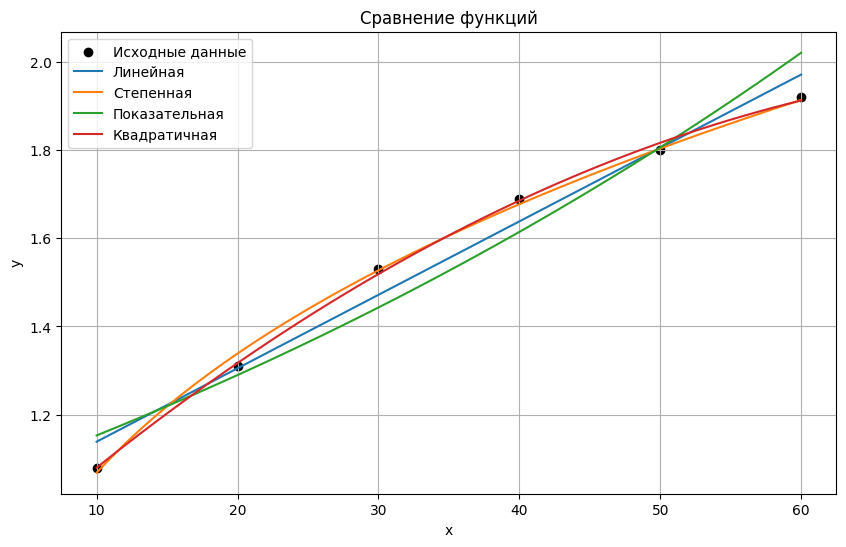

In [7]:
x_plot = np.linspace(df['x'].min(), df['x'].max())

plt.figure(figsize=(10, 6))
plt.scatter(df['x'], df['y'], color='black', label='Исходные данные')
plt.plot(x_plot, a * x_plot + b, label='Линейная')
plt.plot(x_plot, b_stepen * x_plot ** a_stepen, label='Степенная')
plt.plot(x_plot, beta_exp * np.exp(a_exp * x_plot), label='Показательная')
plt.plot(x_plot, a_quad * x_plot**2 + b_quad * x_plot + c_quad,label='Квадратичная')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Сравнение функций')
plt.grid()
plt.legend()
plt.show()

In [8]:
errors = pd.DataFrame({
    'Func': ['Линейная', 'Степенная', 'Показательная', 'Квадратичная'],
    'Error': [error, error_stepen, error_exp, error_quad]
})

errors.sort_values(by='Error')

,Func,Error
3,Квадратичная,0.000526
1,Степенная,0.001173
0,Линейная,0.012194
2,Показательная,0.029203


**Вывод:** Лучшвя фунция - квадратная